<a href="https://colab.research.google.com/github/fdegolla/MAT-422-Francisco-Degollado/blob/main/MAT422_HW_3_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# MAT 422 - Homework 3.3

**Name:** Francisco Degollado

## Topics

- 3.3.1 Necessary and Sufficient Conditions of Local Minimizers
- 3.3.2 Convexity and Global Minimizers
- 3.3.3 Gradient Descent

## 3.3.1 Necessary and Sufficient Conditions of Local Minimizers

A local minimizer is a point where a function has a value less than or equal to the values at nearby points.

For a differentiable function, a necessary condition for an interior local minimum at $x=a$ is

$$
f'(a)=0.
$$

However, this condition alone does not guarantee a local minimum.

For a twice-differentiable function, a sufficient condition for a strict local minimum is

$$
f'(a)=0
$$

and

$$
f''(a)>0.
$$

Consider the function

$$
f(x)=x^2-4x+5.
$$

The first derivative is

$$
f'(x)=2x-4.
$$

Setting the first derivative equal to zero gives

$$
2x-4=0 \implies x=2.
$$

The second derivative is

$$
f''(x)=2.
$$

Since $f''(2)=2>0$, the second derivative test confirms that $x=2$ is a strict local minimizer.

Evaluating the function gives

$$
f(2)=2^2-4(2)+5=1.
$$

Therefore, the local minimum occurs at $(2,1)$.

We can use Python to calculate the critical point, verify the second derivative condition, and graph the function.

In [2]:
# Define the symbolic variable
x = sp.symbols('x')

# Define the function
f = x**2 - 4*x + 5

# Calculate the first and second derivatives
f_prime = sp.diff(f, x)
f_double_prime = sp.diff(f_prime, x)

# Find critical points
critical_points = sp.solve(f_prime, x)

print("Original function:")
print(f)

print("\nFirst derivative:")
print(f_prime)

print("\nSecond derivative:")
print(f_double_prime)

print("\nCritical points:")
print(critical_points)

# Evaluate the second derivative at the critical point
for point in critical_points:
    second_derivative_value = f_double_prime.subs(x, point)
    function_value = f.subs(x, point)

    print("\nCritical point:", point)
    print("Second derivative:", second_derivative_value)
    print("Function value:", function_value)

    if second_derivative_value > 0:
        print("Classification: Local minimum")
    elif second_derivative_value < 0:
        print("Classification: Local maximum")
    else:
        print("Classification: Inconclusive")

Original function:
x**2 - 4*x + 5

First derivative:
2*x - 4

Second derivative:
2

Critical points:
[2]

Critical point: 2
Second derivative: 2
Function value: 1
Classification: Local minimum


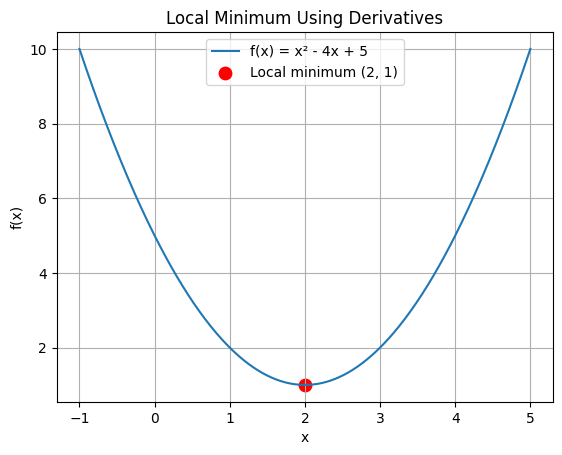

In [3]:

# Convert the symbolic function to a numerical function
f_numeric = sp.lambdify(x, f, "numpy")

# Create x-values
x_values = np.linspace(-1, 5, 400)

# Calculate y-values
y_values = f_numeric(x_values)

# Plot the function
plt.plot(x_values, y_values, label="f(x) = x² - 4x + 5")

# Mark the local minimum
plt.scatter(2, 1, color="red", s=80, label="Local minimum (2, 1)")

# Add labels and title
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Local Minimum Using Derivatives")

# Add legend and grid
plt.legend()
plt.grid()

plt.show()


### Interpretation

The function

$$
f(x)=x^2-4x+5
$$

has a critical point at \(x=2\), where the first derivative equals zero:

$$
f'(2)=0.
$$

Since the second derivative is

$$
f''(2)=2>0,
$$

the second derivative test confirms that the critical point is a strict local minimum.

The minimum function value is

$$
f(2)=1.
$$

The graph illustrates this result by showing an upward-opening parabola with its lowest point at \((2,1)\).

## 3.3.2 Convexity and Global Minimizers

A function is convex if the line segment connecting any two points on its graph lies on or above the graph.

For a twice-differentiable function, if

$$
f''(x)\geq 0
$$

for all \(x\) in an interval, then the function is convex on that interval.

An important property of convex functions is that every local minimum is also a global minimum.

Consider the function

$$
f(x)=x^2-6x+10.
$$

Its first and second derivatives are

$$
f'(x)=2x-6
$$

and

$$
f''(x)=2.
$$

Since \(f''(x)>0\) for all \(x\), the function is strictly convex. We can use Python to find its critical point and verify that it is a global minimum.

In [4]:

# Define the variable and function
x = sp.symbols('x')
f = x**2 - 6*x + 10

# Calculate derivatives
f_prime = sp.diff(f, x)
f_double_prime = sp.diff(f_prime, x)

# Find critical points
critical_points = sp.solve(f_prime, x)

print("Original function:")
print(f)

print("\nFirst derivative:")
print(f_prime)

print("\nSecond derivative:")
print(f_double_prime)

print("\nCritical points:")
print(critical_points)

# Evaluate the minimum
x_min = critical_points[0]
y_min = f.subs(x, x_min)

print("\nGlobal minimum occurs at x =", x_min)
print("Minimum function value =", y_min)

# Verify convexity
print("\nClassification:",
      "Strictly convex" if f_double_prime > 0 else "Not verified")


Original function:
x**2 - 6*x + 10

First derivative:
2*x - 6

Second derivative:
2

Critical points:
[3]

Global minimum occurs at x = 3
Minimum function value = 1

Classification: Strictly convex


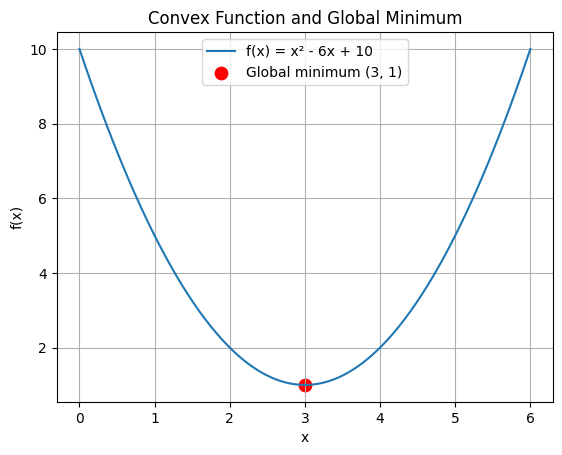

In [5]:

# Convert the symbolic function to a numerical function
f_numeric = sp.lambdify(x, f, "numpy")

# Create x-values
x_values = np.linspace(0, 6, 400)

# Calculate y-values
y_values = f_numeric(x_values)

# Plot the convex function
plt.plot(x_values, y_values, label="f(x) = x² - 6x + 10")

# Mark the global minimum
plt.scatter(3, 1, color="red", s=80,
            label="Global minimum (3, 1)")

# Add labels and title
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Convex Function and Global Minimum")

# Add legend and grid
plt.legend()
plt.grid()

plt.show()


### Interpretation

The function

$$
f(x)=x^2-6x+10
$$

has a critical point at

$$
x=3,
$$

where

$$
f'(3)=0.
$$

Since the second derivative satisfies

$$
f''(x)=2>0,
$$

the function is strictly convex for all real numbers.

Therefore, the critical point is the unique global minimizer, with a minimum function value of

$$
f(3)=1.
$$

The graph confirms this result by showing an upward-opening parabola with its lowest point at

$$
(3,1).
$$

## 3.3.3 Gradient Descent

Gradient descent is an iterative optimization method used to find the minimum of a function. It works by repeatedly updating the current estimate in the direction opposite to the gradient.

For a function of one variable, the gradient descent formula is

$$
x_{n+1}=x_n-\alpha f'(x_n)
$$

where:

where:

- xₙ is the current estimate.
- α is the learning rate.
- f′(xₙ) is the derivative evaluated at the current estimate.

Consider the function

$$
f(x)=x^2-6x+10
$$

Its first derivative is

$$
f'(x)=2x-6
$$

The function has a global minimum at

$$
x=3
$$

with a minimum function value of

$$
f(3)=1
$$

We can use Python to apply gradient descent starting at an initial value of 0, with a learning rate of 0.1, and observe how the estimates approach the global minimum.

In [6]:

# Define the function and its derivative
def f(x):
    return x**2 - 6*x + 10

def gradient(x):
    return 2*x - 6

# Set gradient descent parameters
learning_rate = 0.1
x_current = 0.0
iterations = 30

# Store values at each iteration
x_history = [x_current]
f_history = [f(x_current)]

# Perform gradient descent
for i in range(iterations):
    x_current = x_current - learning_rate * gradient(x_current)

    x_history.append(x_current)
    f_history.append(f(x_current))

# Display the results
print("Initial x =", x_history[0])
print("Learning rate =", learning_rate)
print("Number of iterations =", iterations)

print("\nFinal x =", round(x_current, 6))
print("Final function value =", round(f(x_current), 6))

print("\nActual minimum occurs at x = 3")
print("Actual minimum function value = 1")


Initial x = 0.0
Learning rate = 0.1
Number of iterations = 30

Final x = 2.996286
Final function value = 1.000014

Actual minimum occurs at x = 3
Actual minimum function value = 1


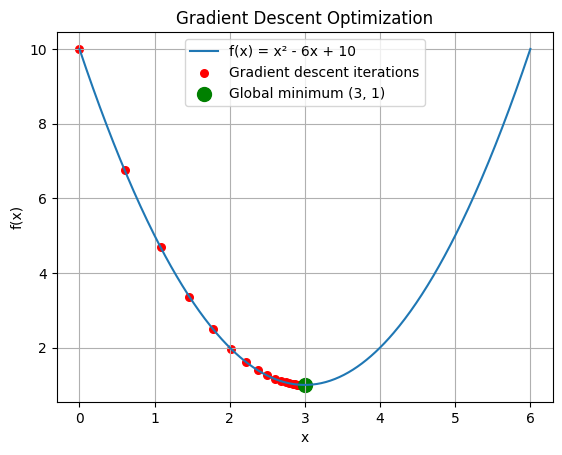

In [7]:

# Create x-values for the function
x_values = np.linspace(0, 6, 400)
y_values = f(x_values)

# Plot the original function
plt.plot(x_values, y_values,
         label="f(x) = x² - 6x + 10")

# Plot the gradient descent iterations
plt.scatter(x_history, f_history,
            color="red", s=30,
            label="Gradient descent iterations")

# Mark the global minimum
plt.scatter(3, 1, color="green", s=100,
            label="Global minimum (3, 1)")

# Add labels and title
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Gradient Descent Optimization")

# Add legend and grid
plt.legend()
plt.grid()

plt.show()


### Interpretation

Gradient descent was applied to the function

$$
f(x)=x^2-6x+10
$$

using an initial value of 0 and a learning rate of 0.1.

After 30 iterations, the algorithm produced an approximate minimizer of

$$
x\approx 2.996286
$$

with a corresponding function value of

$$
f(x)\approx 1.000014
$$

The actual global minimum occurs at

$$
x=3
$$

where

$$
f(3)=1
$$

The results show that gradient descent approaches the global minimum through repeated updates. The graph illustrates how the estimates move toward the lowest point of the convex function.

## Conclusion

In this assignment, we uses Python to demonstrate three important concepts in mathematical optimization. The first one was local minimizers. The second concept was convexity and global minimizers. Then finally we observed gradient descent. In Section 3.3.1, the first and second derivatives were used to identify and classify a local minimum. In Section 3.3.2, convexity was used to verify that a critical point was also the unique global minimum. Finally, in Section 3.3.3, gradient descent was used to approximate the global minimum through repeated iterations. These examples highlighted the importance of understanding both the theoretical foundations of optimization and the computational methods we use to solve these types of problems.